In [60]:
import numpy as np
import pandas as pd
from pandas import Series,DataFrame
import matplotlib.pyplot as plt
%matplotlib inline
import re


In [178]:
a = '32423098'
r = re.search("^\d+$",str(a))
# r.has
dir(r)
r.endpos

8

In [124]:
data = pd.read_excel('./datas/18级高一体测成绩汇总.xls')

#将'6班'替换成‘6’
data.loc[data[data['班级'] == '6班'].index,['班级']] = 6
#将班级列中非数字的行删除掉
data = data[~data['班级'].apply( lambda x: x if re.search("^\d+$",str(x)) else np.nan ).isnull()]
#将空值替换成0
data.fillna(0,inplace=True)

In [125]:
#将几分几秒转换成浮点数的分钟
def convert(x):
    if isinstance(x,str):
        minute,second = x.split("'")
        minute = int(minute)
        second = int(second)
        return minute + second/100.0
    else:
        return x
    
data.loc[:,['1000米']] = data['1000米'].map(convert)


In [149]:
data.columns = ['班级', '性别', '姓名', '男1000', '男50米跑', '跳远', '体前屈', '引体', '肺活量', '身高', '体重']
data['男50米跑'] = data['男50米跑'].astype(np.float)

,班级,性别,姓名,1000米,50米,跳远,体前屈,引体,肺活量,身高,体重
0,1,男,高孜阳0611,4.13,8.88,195.0,12,1,2785,170.0,72.6
1,1,男,郝少杰1013,4.16,7.70,225.0,11,7,3133,174.0,52.7
2,1,男,郝梓烨0619,4.09,8.45,218.0,14,1,3901,169.0,46.5
3,1,男,何弘源1010,4.21,8.05,206.0,13,1,4946,183.0,79.7
4,1,男,刘硕鹏1212,3.44,7.52,210.0,13,9,3538,171.0,54.7
...,...,...,...,...,...,...,...,...,...,...,...
488,17,男,张乔楠0311,4.23,8.27,208.0,10,0,4647,176.0,69.5
489,17,男,郭泽森0333,5.19,9.55,210.0,15,6,7042,177.0,76.0
490,17,男,陈子龙061X,3.25,7.5,252.0,13,13,5755,181.0,65.0
491,17,男,王丹龙0636,4.39,7.81,208.0,14,11,5688,172.0,51.7


In [136]:
score = pd.read_excel('./datas/体侧成绩评分表.xls',header=[0,1])

In [143]:
def convert(x):
    m,s = x.strip('"').split("'")
    m,s = int(m),int(s)
    return m + s/100.0
score.iloc[:,-4] = score.iloc[:,-4].map(convert)
score.iloc[:,-2] = score.iloc[:,-2].map(convert)

男肺活量       女肺活量      男50米跑      女50米跑       男体前屈       ...  女跳远        男引体      女仰卧      男1000        女800     
      成绩   分数    成绩   分数    成绩   分数    成绩   分数    成绩   分数  ...   成绩   分数    成绩   分数  成绩   分数    成绩   分数     成绩   分数
0   4540  100  3150  100   7.1  100   7.8  100  23.6  100  ...  204  100  16.0  100  53  100  3.30  100  3'24"  100
1   4420   95  3100   95   7.2   95   7.9   95  21.5   95  ...  198   95  15.0   95  51   95  3.35   95  3'30"   95
2   4300   90  3050   90   7.3   90   8.0   90  19.4   90  ...  192   90  14.0   90  49   90  3.40   90  3'36"   90
3   4050   85  2900   85   7.4   85   8.3   85  17.2   85  ...  185   85  13.0   85  46   85  3.47   85  3'43"   85
4   3800   80  2750   80   7.5   80   8.6   80  15.0   80  ...  178   80  12.0   80  43   80  3.55   80  3'50"   80
5   3680   78  2650   78   7.7   78   8.8   78  13.6   78  ...  175   78   NaN   78  41   78  4.00   78  3'55"   78
6   3560   76  2550   76   7.9   76   9.0   76  12.2   76  ...  172   76  11.0   76  39   76  4.05   76  4'00"   76
7   3440   74  2450   74   8.1   74   9.2   74  10.8   74  ...  169   74   NaN   74  37   74  4.10   74  4'05"   74
8   3320   72  2350   72   8.3   72   9.4   72   9.4   72  ...  166   72  10.0   72  35   72  4.15   72  4'10"   72
9   3200   70  2250   70   8.5   70   9.6   70   8.0   70  ...  163   70   NaN   70  33   70  4.20   70  4'15"   70
10  3080   68  2150   68   8.7   68   9.8   68   6.6   68  ...  160   68   9.0   68  31   68  4.25   68  4'20"   68
11  2960   66  2050   66   8.9   66  10.0   66   5.2   66  ...  157   66   NaN   66  29   66  4.30   66  4'25"   66
12  2840   64  1950   64   9.1   64  10.2   64   3.8   64  ...  154   64   8.0   64  27   64  4.35   64  4'30"   64
13  2720   62  1850   62   9.3   62  10.4   62   2.4   62  ...  151   62   NaN   62  25   62  4.40   62  4'35"   62
14  2600   60  1750   60   9.5   60  10.6   60   1.0   60  ...  148   60   7.0   60  23   60  4.45   60  4'40"   60
15  2470   50  1710   50   9.7   50  10.8   50   0.0   50  ...  143   50   6.0   50  21   50  5.05   50  4'50"   50
16  2340   40  1670   40   9.9   40  11.0   40  -1.0   40  ...  138   40   5.0   40  19   40  5.25   40  5'00"   40
17  2210   30  1630   30  10.1   30  11.2   30  -2.0   30  ...  133   30   4.0   30  17   30  5.45   30  5'10"   30
18  2080   20  1590   20  10.3   20  11.4   20  -3.0   20  ...  128   20   3.0   20  15   20  6.05   20  5'20"   20
19  1950   10  1550   10  10.5   10  11.6   10  -4.0   10  ...  123   10   2.0   10  13   10  6.25   10  5'30"   10

[20 rows x 24 columns]

In [220]:
%%time
#加入 '男1000', '男50米跑' 对应的分数
for col in ['男1000', '男50米跑']:
    s = score[col]
    
    def convert(x):
        for i in range(len(s)):
            if x <= s['成绩'].iloc[0]:
                if x == 0 :
                    return 0
                return 100
            elif x > s['成绩'].iloc[-1]:
                return 0
            elif (x > s['成绩'].iloc[i-1] ) and (x <= s['成绩'].iloc[i]):
                return s['分数'][i]
    
    data[col + '成绩'] = data[col].map(convert)

Wall time: 373 ms


In [222]:
%%time
#加入对应列的分数
for col in ['跳远', '体前屈', '引体', '肺活量']:
    if col == '跳远':
        s = score["男" + col]
    elif col == '体前屈':
        s = score['男体前屈']
    elif col == '引体':
        s = score['男引体']
    elif col == '肺活量':
        s = score['男肺活量']
    
    def convert(x):
        if x >= s['成绩'].iloc[0]:
            return 100
        elif x < s['成绩'].iloc[-1]:
            return 0
        else:
            pos = np.max(np.where(s['成绩'].values > x))
            return s['分数'][pos + 1]
        
    data[col + '成绩'] = data[col].map(convert)
    
    

Wall time: 190 ms


In [240]:
def convert(x):
    return x if x < 10 else x/100.0

data['身高'] = data['身高'].map(convert)
data['BMI'] = (data['体重']/(data['身高']**2)).round(3)

In [242]:

data['BMI_score'] = data['BMI'].map(lambda x: 100 if x >= 16.5 and x <= 23.2 else (80 if x <16.5 or x >= 23.3 and x <= 26.3 else 60)   )

In [243]:
data

,班级,性别,姓名,男1000,男50米跑,跳远,体前屈,引体,肺活量,身高,体重,男1000成绩,男50米跑成绩,跳远成绩,体前屈成绩,引体成绩,肺活量成绩,BMI,BMI_score
0,1,男,高孜阳0611,4.13,8.88,195.0,12,1,2785,1.70,72.6,72,66,60,74,0,62,25.121,80
1,1,男,郝少杰1013,4.16,7.70,225.0,11,7,3133,1.74,52.7,70,78,74,74,62,68,17.407,100
2,1,男,郝梓烨0619,4.09,8.45,218.0,14,1,3901,1.69,46.5,74,70,70,78,0,80,16.281,80
3,1,男,何弘源1010,4.21,8.05,206.0,13,1,4946,1.83,79.7,68,74,64,76,0,100,23.799,80
4,1,男,刘硕鹏1212,3.44,7.52,210.0,13,9,3538,1.71,54.7,85,78,66,76,70,74,18.707,100
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
488,17,男,张乔楠0311,4.23,8.27,208.0,10,0,4647,1.76,69.5,68,72,66,72,0,100,22.437,100
489,17,男,郭泽森0333,5.19,9.55,210.0,15,6,7042,1.77,76.0,40,50,66,80,50,100,24.259,80
490,17,男,陈子龙061X,3.25,7.50,252.0,13,13,5755,1.81,65.0,100,80,90,76,85,100,19.841,100
491,17,男,王丹龙0636,4.39,7.81,208.0,14,11,5688,1.72,51.7,62,76,66,78,78,100,17.476,100


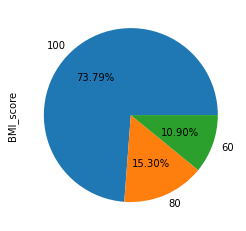

In [245]:
(data['BMI_score'].value_counts()).plot(kind = 'pie',autopct='%0.2f%%')

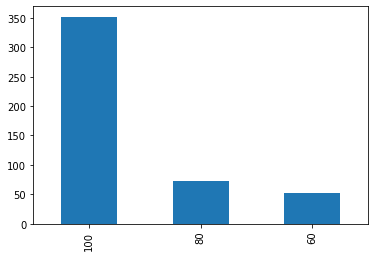

In [246]:
(data['BMI_score'].value_counts()).plot(kind = 'bar')

d:\app\python\python38\lib\site-packages\matplotlib\backends\backend_agg.py:214: RuntimeWarning: Glyph 30007 missing from current font.
  font.set_text(s, 0.0, flags=flags)
d:\app\python\python38\lib\site-packages\matplotlib\backends\backend_agg.py:214: RuntimeWarning: Glyph 25104 missing from current font.
  font.set_text(s, 0.0, flags=flags)
d:\app\python\python38\lib\site-packages\matplotlib\backends\backend_agg.py:214: RuntimeWarning: Glyph 32489 missing from current font.
  font.set_text(s, 0.0, flags=flags)
d:\app\python\python38\lib\site-packages\matplotlib\backends\backend_agg.py:183: RuntimeWarning: Glyph 30007 missing from current font.
  font.set_text(s, 0, flags=flags)
d:\app\python\python38\lib\site-packages\matplotlib\backends\backend_agg.py:183: RuntimeWarning: Glyph 25104 missing from current font.
  font.set_text(s, 0, flags=flags)
d:\app\python\python38\lib\site-packages\matplotlib\backends\backend_agg.py:183: RuntimeWarning: Glyph 32489 missing from current font.
  f

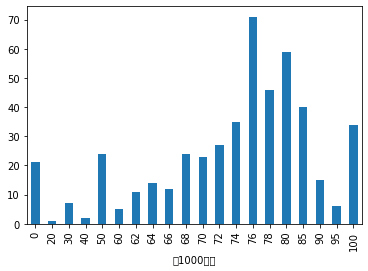

In [248]:
data.groupby(['男1000成绩'])['BMI_score'].count().plot(kind='bar')